# **Data Loading & Batch 학습**

## **왜 데이터를 나눠서 학습하는가?**

전체 데이터를 한 번에 신경망에 넣으면 두 가지 문제가 생깁니다.

- **메모리 부족** — 대용량 데이터는 GPU/CPU 메모리에 다 올릴 수 없습니다.
- **학습 불안정** — 전체 평균 기울기만 사용하면 Local Minimum에 빠지기 쉽습니다.

그래서 데이터를 **작은 묶음(Batch)** 으로 나눠서 반복 학습합니다.

## **핵심 용어 정리**

| 용어 | 의미 | 예시 (데이터 1000개, batch_size=100) |
|------|------|--------------------------------------|
| **Epoch** | 전체 데이터를 1번 다 본 것 | 1 epoch |
| **Batch** | 한 번에 처리하는 데이터 묶음 | 100개짜리 묶음 |
| **Iteration** | 1 Batch로 파라미터를 1번 업데이트 | 1 iteration |
| **Steps per Epoch** | 1 Epoch 안의 총 iteration 수 | 1000 ÷ 100 = **10** |

```
1 Epoch = 데이터 수 ÷ batch_size iterations
```

In [1]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, TensorDataset
import numpy as np
import matplotlib.pyplot as plt
import math

torch.manual_seed(42)
np.random.seed(42)

## **1. 데이터 준비**

`make_classification`으로 이진 분류용 랜덤 데이터를 생성합니다.

| 파라미터 | 설명 |
|----------|------|
| `n_samples` | 총 데이터 수 |
| `n_features` | 특징(입력) 수 |
| `n_informative` | 실제로 분류에 유용한 특징 수 |
| `n_redundant` | 유용한 특징의 선형 조합으로 만들어진 중복 특징 수 |

In [2]:
from sklearn.datasets import make_classification

X_np, y_np = make_classification(
    n_samples=1000,
    n_features=10,
    n_informative=6,
    n_redundant=2,
    random_state=42
)

print("X shape:", X_np.shape)   # (1000, 10)
print("y shape:", y_np.shape)   # (1000,)

X shape: (1000, 10)
y shape: (1000,)


**Q1. 데이터를 train/test로 나누고 스케일링을 적용하세요.**

- test_size=0.3, random_state=42
- StandardScaler는 train 기준으로 fit 후 test에 transform만 적용합니다.

In [3]:
# code here
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(X_np, y_np, test_size=0.3, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("학습 데이터:", X_train.shape)
print("테스트 데이터:", X_test.shape)

학습 데이터: (700, 10)
테스트 데이터: (300, 10)


**Q2. 모든 데이터를 텐서로 바꿔주세요.**

In [4]:
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32).reshape(-1,1)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32).reshape(-1,1)

## **2. TensorDataset & DataLoader**

TensorDataset : X, y tensor를 하나의 데이터셋으로 묶는다.

DataLoader : 데이터셋 묶음을 batch 단위로 커내주는 반복자이다.

| 파라미터 | 설명 | 권장값 |
|----------|------|--------|
| `batch_size` | 한 번에 꺼낼 데이터 수 | 32 ~ 256 |
| `shuffle` | 매 epoch마다 순서를 섞을지 | 학습: `True`, 평가: `False` |
| `drop_last` | 마지막 배치가 작을 때 버릴지 | BatchNorm 사용 시 `True` 권장 |

```
from torch.utils.data import Dataset, DataLoader, TensorDataset
```

**Q1. 학습 데이터를 TensorDataset을 활용하여 하나로 묶는다.**

In [5]:
from torch.utils.data import Dataset, DataLoader, TensorDataset
dataset = TensorDataset(X_train_tensor, y_train_tensor)

**Q2. 하나로 묶은 데이터셋을 DataLoader에 투입한다.**

- batch_size=32
- shuffle=True

In [6]:
loader  = DataLoader(dataset, batch_size=32, shuffle=True)

**Q3. 첫번째 batch를 가져와서 출력한다.**

```
X_batch, y_batch = next(iter(loader))
```
- next() : iterable의 다음 요소에 접근한다.
- iter() : 그룹화되어있는 객체를 iterable로 변환한다.

In [16]:
X_batch, y_batch = next(iter(loader))
print("배치 X shape:", X_batch.shape)   # (32, 10)
print("배치 y shape:", y_batch.shape)   # (32, 1)
print("총 배치 수  :", len(loader))

배치 X shape: torch.Size([1, 10])
배치 y shape: torch.Size([1, 1])
총 배치 수  : 700


## **3. Data Loading 전략**

같은 데이터, 같은 모델로 3가지 방식의 차이를 눈으로 확인합니다.

DataLoader (batch)를 사용한 전체 학습 루프
```
for epoch in range(num_epochs):          ← 전체 반복
    model.train()
    for X_batch, y_batch in loader:      ← 배치 반복 (1 epoch)
        forward → loss → zero_grad → backward → step

    model.eval()
    with torch.no_grad():                ← 평가
        ...
```


**Q1. 기본 모델을 생성해주세요.**

- Linear(10,32) -> ReLU() -> Linear(32, 1) -> Sigmoid()

In [17]:
# 기본 모델
class SimpleNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(10, 32),
            nn.ReLU(),
            nn.Linear(32, 1),
            nn.Sigmoid()
        )
    def forward(self, x):
      return self.net(x)

**Q2. Loss (criterion)을 BCELoss()로 설정해주세요.**

In [18]:
# code here
criterion = nn.BCELoss()

**Q3. 모델을 생성하고 층이 잘 구성되어있는지 출력합니다.**

In [19]:
# code here
model = SimpleNet()
print(model)

SimpleNet(
  (net): Sequential(
    (0): Linear(in_features=10, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=1, bias=True)
    (3): Sigmoid()
  )
)


**3가지 Gradient Descent 방식**

| 방식 | 업데이트 단위 | 안정성 | 속도 | 실무 사용 |
|------|-------------|--------|------|-----------|
| **Batch GD** | 전체 데이터 | 높음 | 느림 | ❌ |
| **Stochastic GD (SGD)** | 1개 | 낮음 (노이즈 많음) | 빠름 | ❌ |
| **Mini-batch GD** | 소묶음 (32~256) | 중간 | 빠름 | ✅ |

- PyTorch의 `DataLoader(batch_size=N)` 이 Mini-batch GD를 구현한 것입니다.  
- torch.optim.SGD는 배치를 나누지 않습니다 — 배치를 나누는 건 DataLoader의 역할입니다.

### **3.1 Batch GD**

전체 데이이터를 한 번에 투입하여 학습시킨다.
- 원래 하던대로 학습시키면 된다.
- DataLoading을 한 loader는 사용하지 않는다.
- epoch : 100
- 그리고 각 epoch당 loss를 losses_bgd 리스트에 저장한다.

In [20]:
loader  = DataLoader(dataset)

In [25]:
losses_bgd = []
model = SimpleNet()
bgd = torch.optim.SGD(model.parameters(), lr=0.1) # learning rate = 0.1
cnt = 0

In [26]:
for epoch in range(100):
    model.train()
    pred = model(X_train_tensor)       # 전체 데이터 한 번에
    loss = criterion(pred, y_train_tensor)
    bgd.zero_grad()
    loss.backward()
    bgd.step()
    losses_bgd.append(loss.item())
    if (epoch + 1) % 10 == 0:
        print(f"epoch {epoch+1:3d} | loss: {losses_bgd[-1]:.4f}")
    cnt += 1

print(f"총 iterations : {cnt}")
print(f"Batch GD   | epoch당 업데이트: 1회 | 최종 loss: {losses_bgd[-1]:.4f}")

epoch  10 | loss: 0.6483
epoch  20 | loss: 0.5869
epoch  30 | loss: 0.5347
epoch  40 | loss: 0.4901
epoch  50 | loss: 0.4538
epoch  60 | loss: 0.4255
epoch  70 | loss: 0.4038
epoch  80 | loss: 0.3872
epoch  90 | loss: 0.3741
epoch 100 | loss: 0.3638
총 iterations : 100
Batch GD   | epoch당 업데이트: 1회 | 최종 loss: 0.3638


In [ ]:
from sklearn.metrics import accuracy_score
with torch.no_grad():
  y_pred = model(X_test_tensor)
  print(accuracy_score(y_test, np.where(y_pred >= 0.5, 1, 0)))

0.82


### **3.2 Stochastic GD**
- 데이터 한 개 마다 업데이트를 시킨다.
- 즉, batch_size=1이 된다는 것이다.

In [28]:
loader = DataLoader(
    TensorDataset(X_train_tensor, y_train_tensor),
    batch_size=1, shuffle=True
)

In [29]:
losses_sgd = []
model = SimpleNet()
sgd = torch.optim.SGD(model.parameters(), lr=0.1) # learning rate = 0.1
cnt = 0

In [ ]:
for epoch in range(100):
    model.train()
    epoch_loss = 0
    for X_b, y_b in loader:
        pred = model(X_b)
        loss = criterion(pred, y_b)
        sgd.zero_grad()
        loss.backward()
        sgd.step()
        epoch_loss += loss.item()
        cnt += 1
    losses_sgd.append(epoch_loss / len(loader))
    if (epoch + 1) % 10 == 0:
        print(f"epoch {epoch+1:3d} | loss: {losses_sgd[-1]:.4f}")

print(f"총 iterations : {cnt}")
print(f"SGD        | epoch당 업데이트: {len(loader)}회 | 최종 loss: {losses_sgd[-1]:.4f}")

epoch  10 | loss: 0.2269
epoch  20 | loss: 0.1757
epoch  30 | loss: 0.1464
epoch  40 | loss: 0.0931
epoch  50 | loss: 0.0875
epoch  60 | loss: 0.0901
epoch  70 | loss: 0.0349
epoch  80 | loss: 0.0248
epoch  90 | loss: 0.0071
epoch 100 | loss: 0.0025
총 iterations : 70000
SGD        | epoch당 업데이트: 700회 | 최종 loss: 0.0025


In [18]:
from sklearn.metrics import accuracy_score
with torch.no_grad():
  y_pred = model(X_test_tensor)
  print(accuracy_score(y_test, np.where(y_pred >= 0.5, 1, 0)))

0.92


### **3.3 Mini-batch GD**

In [19]:
mb_loader = DataLoader(
    TensorDataset(X_train_tensor, y_train_tensor),
    batch_size=32, shuffle=True       # 32개씩
)

In [20]:
losses_mb = []
model = SimpleNet()
mbgd = torch.optim.SGD(model.parameters(), lr=0.1) # learning rate = 0.1
cnt = 0

In [21]:
for epoch in range(100):
    model.train()
    epoch_loss = 0
    for X_b, y_b in mb_loader:
        pred = model(X_b)
        loss = criterion(pred, y_b)
        mbgd.zero_grad()
        loss.backward()
        mbgd.step()
        epoch_loss += loss.item()
        cnt += 1
    losses_mb.append(epoch_loss / len(mb_loader))
    if (epoch + 1) % 10 == 0:
        print(f"epoch {epoch+1:3d} | loss: {losses_mb[-1]:.4f}")

print(f"총 iterations : {cnt}")
print(f"Mini-batch | epoch당 업데이트: {len(mb_loader)}회 | 최종 loss: {losses_mb[-1]:.4f}")

epoch  10 | loss: 0.3214
epoch  20 | loss: 0.2552
epoch  30 | loss: 0.2181
epoch  40 | loss: 0.2013
epoch  50 | loss: 0.1870
epoch  60 | loss: 0.1764
epoch  70 | loss: 0.1673
epoch  80 | loss: 0.1605
epoch  90 | loss: 0.1538
epoch 100 | loss: 0.1478
총 iterations : 2200
Mini-batch | epoch당 업데이트: 22회 | 최종 loss: 0.1478


In [22]:
from sklearn.metrics import accuracy_score
with torch.no_grad():
  y_pred = model(X_test_tensor)
  print(accuracy_score(y_test, np.where(y_pred >= 0.5, 1, 0)))

0.8833333333333333


### **3.4 세 방식 Loss 시각화**

**Q1. BatchGD, SGD, Mini-Batch GD의 epoch별 loss를 시각화해보자.**

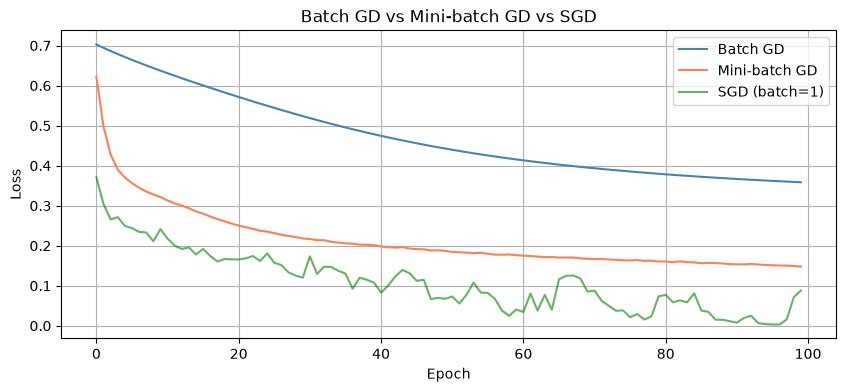

In [23]:
plt.figure(figsize=(10, 4))
plt.plot(losses_bgd, label='Batch GD',      color='steelblue')
plt.plot(losses_mb,  label='Mini-batch GD', color='coral')
plt.plot(losses_sgd, label='SGD (batch=1)', color='green', alpha=0.6)
plt.xlabel('Epoch'); plt.ylabel('Loss')
plt.title('Batch GD vs Mini-batch GD vs SGD')
plt.legend()
plt.grid(True)
plt.show()

## **4. batch_size에 따른 학습 비교**

| batch_size | 기울기 노이즈 | 수렴 | GPU 효율 |
|------------|-------------|------|----------|
| 작을수록 | 많음 → Local Minimum 탈출 유리 | 불안정 | 낮음 |
| 클수록 | 적음 → 안정적 | 빠르고 안정 | 높음 |

**Q1. batch_size를 1, 32, 256, 전체로 바꿔가며 loss 수렴을 비교해보자.**

In [24]:
def train_with_batch(batch_size, epochs=50, lr=0.05):
    torch.manual_seed(42)
    bs     = batch_size if batch_size is not None else len(X_train_tensor)
    loader = DataLoader(TensorDataset(X_train_tensor, y_train_tensor), batch_size=bs, shuffle=True)
    model  = SimpleNet()
    sgd    = torch.optim.SGD(model.parameters(), lr=lr)
    losses = []
    for _ in range(epochs):
        model.train()
        epoch_loss = 0
        for X_b, y_b in loader:
            pred = model(X_b)
            loss = criterion(pred, y_b)
            sgd.zero_grad()
            loss.backward()
            sgd.step()
            epoch_loss += loss.item()
        losses.append(epoch_loss / len(loader))
    return losses

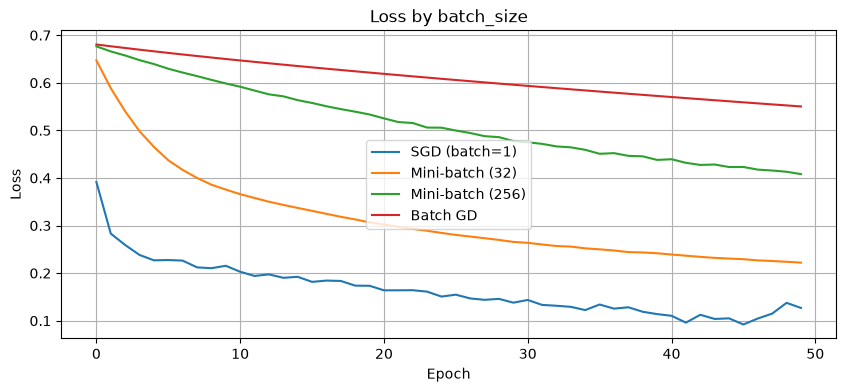

In [25]:
configs = {
    'SGD (batch=1)':    1,
    'Mini-batch (32)':  32,
    'Mini-batch (256)': 256,
    'Batch GD':  None,
}

plt.figure(figsize=(10, 4))
for label, bs in configs.items():
    plt.plot(train_with_batch(bs), label=label)
plt.xlabel('Epoch'); plt.ylabel('Loss')
plt.title('Loss by batch_size')
plt.legend()
plt.grid(True)
plt.show()